Empty DataFrame
Columns: [customer_age, country_risk, transaction_count, transaction_value, account_age, failed_logins, risk_label]
Index: []
<StringArray>
['low', 'medium', 'high', nan]
Length: 4, dtype: str
<class 'pandas.DataFrame'>
Index: 650 entries, 0 to 657
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   customer_age           650 non-null    float64 
 1   country_risk           650 non-null    str     
 2   transaction_count      650 non-null    int64   
 3   transaction_value      650 non-null    float64 
 4   account_age            650 non-null    float64 
 5   failed_logins          650 non-null    int64   
 6   risk_label             650 non-null    str     
 7   transaction_frequency  650 non-null    category
dtypes: category(1), float64(3), int64(2), str(2)
memory usage: 41.4 KB
None
customer_age             0
country_risk             0
transaction_count        0
transaction_val

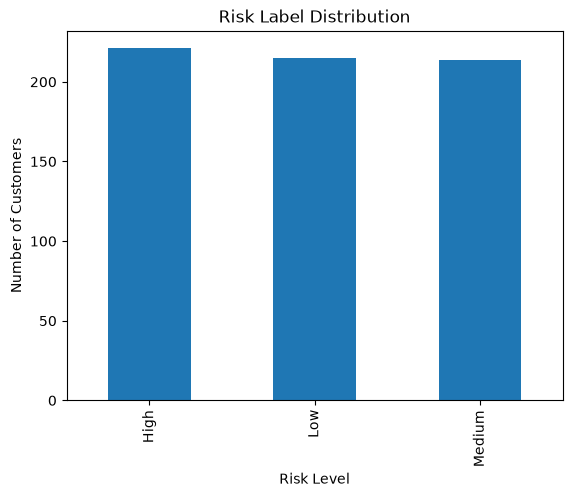

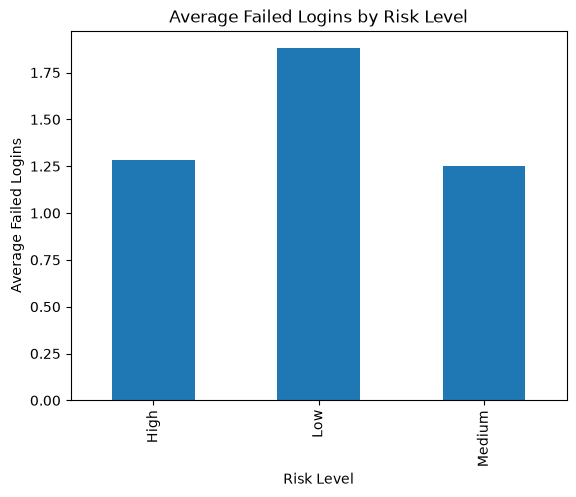

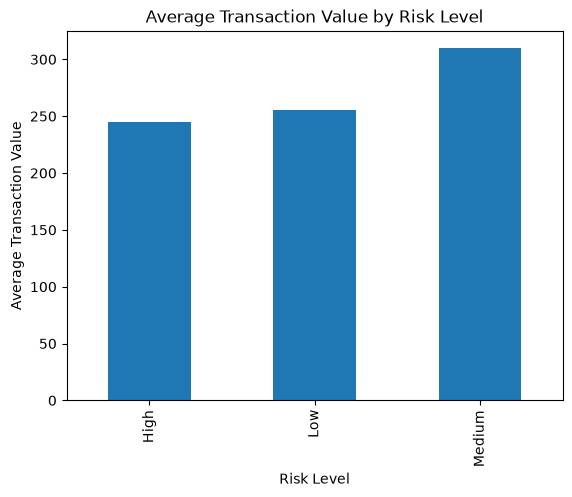

Model : Random Forest
Accuracy: 0.6230769230769231
Precision: 0.6339697802197802
Recall: 0.6230769230769231
F1: 0.626171672228402


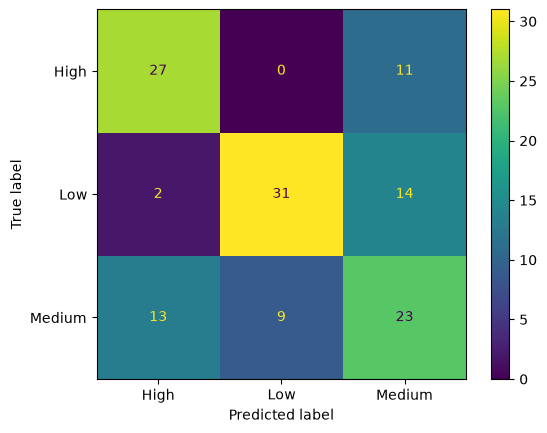

Average failed logins:
risk_label
High      1.285068
Low       1.879070
Medium    1.252336
Name: failed_logins, dtype: float64

Average transaction value:
risk_label
High      244.971946
Low       255.724331
Medium    309.632629
Name: transaction_value, dtype: float64

Risk distribution:
risk_label
High      221
Low       215
Medium    214
Name: count, dtype: int64


In [1]:
import pandas as pd 
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

#Loading csv
data = pd.read_csv("customer_risk_data.csv")

#Removing duplicated data
data = data.drop_duplicates()
print(data[data.duplicated()])

#Correcting wrong/unususal values
data["country_risk"] = data["country_risk"].replace({
        'Low' : 'low',
        'LOW' : 'low',
        'Medium' : 'medium',
        'MEDIUM'  : 'medium',
        'High'   : 'high',
        'HIGH'    : 'high',
        'high'    : 'high',
        ' High' : 'high',
        ' Low' : 'low',
        ' Medium' : 'medium'
})
print(data["country_risk"].unique())

#Missing values
c_agee = data["customer_age"].mean()
trans_val = data["transaction_value"].median()
acc_age = data["account_age"].mean()
c_risk = data["country_risk"].mode()[0]
data.fillna({"customer_age" : c_agee ,
             "transaction_value" : trans_val, 
             "account_age" : acc_age,
             "country_risk" : c_risk
             }, inplace= True)

#Creating a new feature
data["transaction_frequency"] = pd.cut(  #Creating new feature
    data["transaction_count"],
    bins=[0, 10, 30, 50],
    labels=["low", "medium", "high"]
)
print(data.info())
print(data.isnull().sum())

#Separating features and target
label = data[["risk_label"]]

#Encoding features
features = pd.get_dummies(
    data[[
        "customer_age",
        "country_risk",
        "transaction_value",
        "account_age",
        "failed_logins",
        "transaction_frequency"
    ]],
    columns=["country_risk", "transaction_frequency"]
)

#Encoding target
Le = LabelEncoder()
label = Le.fit_transform(data["risk_label"])

#Visualizations
data["risk_label"].value_counts().plot(kind="bar")
plt.title("Risk Label Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.show()
data.groupby("risk_label")["failed_logins"].mean().plot(kind="bar")
plt.title("Average Failed Logins by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Failed Logins")
plt.show()
data.groupby("risk_label")["transaction_value"].mean().plot(kind="bar")
plt.title("Average Transaction Value by Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Average Transaction Value")
plt.show()

#Train model
x_train, x_test, y_train, y_test = train_test_split(features, label , test_size=0.2, random_state=42)
def randomForestModel():
    model = RandomForestClassifier(random_state=42)
    model.fit(x_train, y_train)
    predictions = model.predict(x_test)
    #predicted_risk = Le.inverse_transform(predictions)
    #print("Predictions:" , predicted_risk)
    return predictions

#Check metrics
def checkMetrics(predictions):
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average="weighted")
    recall = recall_score(y_test, predictions, average="weighted")
    f1 = f1_score(y_test, predictions, average="weighted")

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1:", f1)

predictions = randomForestModel()
print("Model : Random Forest")
checkMetrics(predictions)

#Confusion Matrix 
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=Le.classes_
)
disp.plot()
plt.show()

#Findings
print("Average failed logins:")
print(data.groupby("risk_label")["failed_logins"].mean())

print("\nAverage transaction value:")
print(data.groupby("risk_label")["transaction_value"].mean())

print("\nRisk distribution:")
print(data["risk_label"].value_counts())

#Saving cleaned data 
data.to_csv("customer_risk_data_cleaned.csv", index=False)